Device: cpu
GPT-2 Loaded Successfully

TEXT GENERATION

PROMPT: A story about a robot begins like this:

GREEDY:
A robot is a robot that is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed

Temperature: 0.6 Seed: 42
The robot was a humanoid robot with a heart, eyes, and hands that looked like a human, but its skin was red. The robot had a small, muscular body and was very muscular. It was also very slow.

Temperature: 0.6 Seed: 43
The robot, a robot named "The Robot," is trying to figure out what happened to its owner, who is a woman. The robot tries to figure out how to get back to her, and then it has to figure

Temperature: 1.0 Seed: 42
The Robot Man was brought to Earth by the Galactic government, to escape the dark and deadly dangers of space. The robot is the most powerful of all the robots, and even better. It has a long memory for what was

Tempera

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch 1: Loss = 4.9299
Epoch 2: Loss = 4.8760
Epoch 3: Loss = 5.0469

MODEL COMPARISON

Topic: recursion
Base Model: Use the recursion keyword to define a new type of recursion.

Example:

class Recursion { public: Recursion(int i) { return i; } public: Recursion(int i)
Fine-Tuned Model: Use the recursion keyword to define a new type of recursion.

Example:

class Recursion { public: Recursion(int x, int y) { return x + y; } public: Rec

Topic: matrices
Base Model: Use the matrices to create a matrix of the same size as the input.

The following matrix is a matrix of the same size as the input.

The following matrix is a matrix of the same size as
Fine-Tuned Model: Use the matrices to create a matrix of the same size as the input.

The following matrix is a matrix of the same size as the input.

The following matrix is a matrix of the same size as

Topic: binary search
Base Model: Use the search box to find the search term you want to search for.

Study tip: Use the search box to find 

,Topic,Base Model,Fine-Tuned Model
0,recursion,Use the recursion keyword to define a new type...,Use the recursion keyword to define a new type...
1,matrices,Use the matrices to create a matrix of the sam...,Use the matrices to create a matrix of the sam...
2,binary search,Use the search box to find the search term you...,Use the search box to find the search term you...


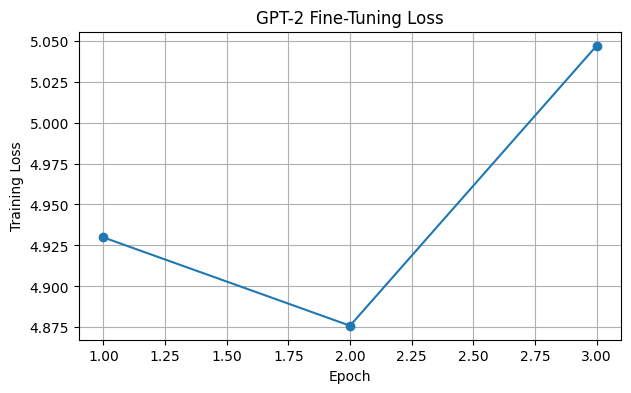


LAB 3 COMPLETED SUCCESSFULLY
Saved Files:
lab_outputs/gpt2_comparison.csv
lab_outputs/gpt2_training_loss.png
lab_outputs/study_tip_gpt2


In [2]:

%pip install -q --no-deps transformers==4.57.1

import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

out = Path("lab_outputs")
out.mkdir(exist_ok=True)

model_id = "openai-community/gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(model_id).to(device)
model.eval()

print("GPT-2 Loaded Successfully")

def generate_text(active_model, prompt, sample=False, temperature=0.8, seed=42):
    torch.manual_seed(seed)

    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    options = {
        "do_sample": sample,
        "max_new_tokens": 45,
        "pad_token_id": tokenizer.eos_token_id
    }

    if sample:
        options.update(temperature=temperature, top_p=0.9)

    active_model.eval()

    with torch.no_grad():
        output = active_model.generate(**inputs, **options)

    return tokenizer.decode(
        output[0, inputs.input_ids.shape[1]:],
        skip_special_tokens=True
    ).strip()

prompts = [
    "A story about a robot begins like this:",
    "In a school library, a tiny robot found a lost book. It"
]

print("\nTEXT GENERATION")

for prompt in prompts:
    print("\nPROMPT:", prompt)
    print("\nGREEDY:")
    print(generate_text(model, prompt))

    for temp in [0.6, 1.0]:
        for seed in [42, 43]:
            print("\nTemperature:", temp, "Seed:", seed)
            print(generate_text(model, prompt, True, temp, seed))

examples = [
    ("graphs", "Sketch a graph, then mark a path through three vertices."),
    ("Python loops", "Trace a loop by writing the counter after each step."),
    ("fractions", "Draw equal parts and label the fraction you shaded."),
    ("sets", "Draw a Venn diagram and label the intersection."),
    ("sorting", "Sort five values by hand and record each swap."),
    ("probability", "List the outcomes of two coin tosses before counting.")
]

tuned = AutoModelForCausalLM.from_pretrained(model_id).to(device)

tuned.requires_grad_(False)
tuned.transformer.h[-1].requires_grad_(True)

optimizer = torch.optim.AdamW(
    tuned.transformer.h[-1].parameters(),
    lr=2e-5
)

loss_history = []

print("\nFINE TUNING")

for epoch in range(3):
    tuned.train()
    total_loss = 0

    for topic, answer in examples:
        prefix = tokenizer.encode(
            f"Topic: {topic}\nStudy tip:"
        )

        target = tokenizer.encode(
            " " + answer
        ) + [tokenizer.eos_token_id]

        ids = torch.tensor([prefix + target], device=device)

        labels = torch.tensor(
            [[-100] * len(prefix) + target],
            device=device
        )

        optimizer.zero_grad()

        loss = tuned(input_ids=ids, labels=labels).loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(examples)
    loss_history.append(avg_loss)

    print(f"Epoch {epoch + 1}: Loss = {avg_loss:.4f}")

tuned.eval()

held_out = ["recursion", "matrices", "binary search"]

results = []

print("\nMODEL COMPARISON")

for topic in held_out:
    prompt = f"Topic: {topic}\nStudy tip:"

    base_output = generate_text(model, prompt)
    tuned_output = generate_text(tuned, prompt)

    print("\nTopic:", topic)
    print("Base Model:", base_output)
    print("Fine-Tuned Model:", tuned_output)

    results.append({
        "Topic": topic,
        "Base Model": base_output,
        "Fine-Tuned Model": tuned_output
    })

df = pd.DataFrame(results)
display(df)

df.to_csv(out / "gpt2_comparison.csv", index=False)

tuned.save_pretrained(out / "study_tip_gpt2")
tokenizer.save_pretrained(out / "study_tip_gpt2")

plt.figure(figsize=(7, 4))
plt.plot(range(1, 4), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("GPT-2 Fine-Tuning Loss")
plt.grid()
plt.savefig(out / "gpt2_training_loss.png")
plt.show()

print("\nLAB 3 COMPLETED SUCCESSFULLY")
print("Saved Files:")
for file in out.iterdir():
    print(file)
